In [13]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
import json
import sys
import time
import analysis_functions
importlib.reload(analysis_functions)
from analysis_functions import pointwise_rmse, pointwise_l1, pointwise_inf


sys.path.insert(0, "..")
from numeric_method.numeric_method import solve_navier_stokes

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "font.serif": ["Computer Modern Roman"],
#     "axes.labelsize": 12,
#     "font.size": 12,
#     "legend.fontsize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
# })

In [67]:
POISSON_MODEL_PATH = "../../models/poisson/2025-11-20_13_03"
CASE_DIR = "../../../data_simple_test/10/params.json"
# CASE_DIR = "../../data/cases/cylinder.json"

with open(CASE_DIR) as f:
    case = json.load(f)

In [68]:
u, p, u_star, div_u_star, phi = solve_navier_stokes(
    case["width"],
    case["height"],
    case["dx"],
    case["dy"],
    case["iterations"],
    case["time_step"],
    case["density"],
    case["viscosity"],
    case["beta"],
    case["geometry"],
    dynamic_time_step=False,
    implicit_laplacian=True,
    return_div_u_star=True,
    method_type="numeric", # numeric, poisson_model, full_model
    # model_path="../../models/full/2025-11-17_11_06"
    model_path="../../models/poisson/2025-11-20_12_15",
    # model_path="../../models/poisson/2025-11-18_13_46"
    poisson_alternation=-1
)

u_ref = u[-1].transpose(2, 0, 1)

c:\Users\gkova\Documents\masters_thesis\src\analysis\..\numeric_method\numeric_method.py:367: SparseEfficiencyWarning: splu converted its input to CSC format
  A_laplacian = splu(A_laplacian)


	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 300/300 [00:01<00:00, 156.22it/s]


In [69]:
u_poisson = []
times = []
alteration_idx = [-1, 100, 50, 25, 10, 5, 2]

for alteration in alteration_idx:
    st = time.time() 

    u, p, u_star, div_u_star, phi = solve_navier_stokes(
        case["width"],
        case["height"],
        case["dx"],
        case["dy"],
        case["iterations"],
        case["time_step"],
        case["density"],
        case["viscosity"],
        case["beta"],
        case["geometry"],
        dynamic_time_step=False,
        implicit_laplacian=True,
        return_div_u_star=True,
        method_type="poisson_model", # numeric, poisson_model, full_model
        # model_path="../../models/full/2025-11-17_11_06"
        model_path="../../models/poisson/2025-11-20_12_15",
        # model_path="../../models/poisson/2025-11-18_13_46"
        poisson_alternation=alteration
    )

    et = time.time()

    u_poisson.append(u[-1].transpose(2, 0, 1))
    times.append(et - st)

	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 300/300 [00:01<00:00, 229.02it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 300/300 [00:01<00:00, 236.22it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


...

     : 100%|██████████| 300/300 [00:01<00:00, 219.39it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 300/300 [00:01<00:00, 205.43it/s]


	 -> Creating discrete Laplacian matrix...
	 -> Iterating...


     : 100%|██████████| 300/300 [00:01<00:00, 165.27it/s]


In [70]:
err_l1 = []
err_l2 = []
err_linf = []

for i in range(len(u_poisson)):
    l1 = pointwise_l1(u_ref, u_poisson[i])
    l2 = pointwise_rmse(u_ref, u_poisson[i])
    linf = pointwise_inf(u_ref, u_poisson[i])

    err_l1.append(l1)
    err_l2.append(l2)
    err_linf.append(linf)

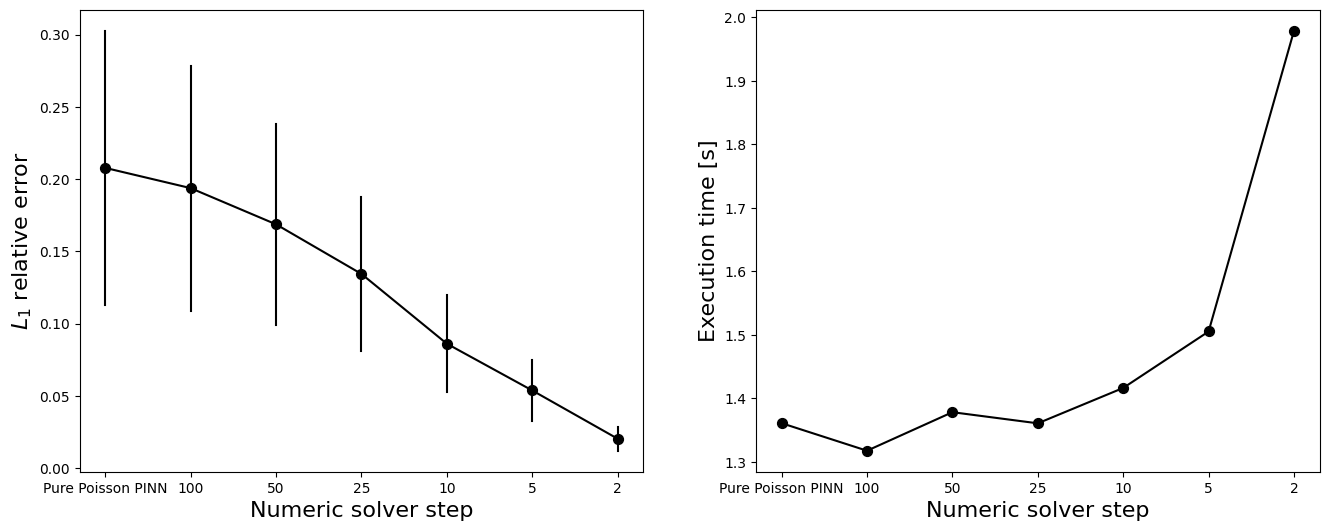

In [71]:
err_mean = np.array([err_l1[i].mean() for i in range(len(err_l1))])
err_std = np.array([err_l1[i].std() for i in range(len(err_l1))])

idx = [i for i in range(len(alteration_idx))]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
ax[0].plot(err_mean, color="black")
ax[0].scatter(idx, err_mean, color="black", s=50)
ax[0].plot([idx, idx], [err_mean - err_std, err_mean + err_std], color="black")

ax[1].plot(times, color="black")
ax[1].scatter(idx, times, color="black", s=50)

labels = alteration_idx
labels[0] = "Pure Poisson PINN"

ax[0].set_xticks(idx)
ax[0].set_xticklabels(labels)

ax[1].set_xticks(idx)
ax[1].set_xticklabels(labels)

ax[0].set_xlabel("Numeric solver step", fontsize=16)
ax[0].set_ylabel(r"$L_1$ relative error", fontsize=16)

ax[1].set_xlabel("Numeric solver step", fontsize=16)
ax[1].set_ylabel("Execution time [s]", fontsize=16)

plt.show()

In [72]:
times

[1.3609285354614258,
 1.317579984664917,
 1.3782622814178467,
 1.360727071762085,
 1.4164447784423828,
 1.50533127784729,
 1.9789936542510986]